# 07 Points of interest and critical facilities
Overture places at tract level: counts and rates, what they scale with, quality fields (confidence, closed places, missing category, supplier), and the fire, EMS and school categories the hidden POI component is built on. The facilities half of that component compares Overture's `categories.primary` counts with an external facility list, so presence and scarcity of these categories matter. Hospitals are tracked but are not part of the hidden score.

In [1]:
from common import *
import duckdb
b = pd.read_parquet(OUT / "base_table.parquet")
s = b[b.region.isin(SCORED)]
c = duckdb.connect(); c.sql("load spatial")
PF = lambda r: f"read_parquet('{(REF/r/f'{r}-overture-pois.parquet').as_posix()}')"
tot = b.groupby("region")[["poi_n", "poi_n_open", "poi_n_closed", "poi_n_nocat", "poi_n_conf05", "poi_n_conf08"]].sum().loc[REG]
print(tot.astype(int).to_string())
print("\nshare of places (%):"); print((100 * tot.div(tot.poi_n, axis=0)).round(1).drop(columns="poi_n").to_string())
print("\nplaces per 1000 residents and per km2 (tract medians):"); print(b.groupby("region")[["poi_per_1000pop", "poi_per_km2", "poi_per_bldg"]].median().loc[REG].round(3).to_string())

                    poi_n  poi_n_open  poi_n_closed  poi_n_nocat  poi_n_conf05  poi_n_conf08
region                                                                                      
maricopa-az        300049      203179          8055        14748        270181        214444
northern-ca        116901       79321          2926         4795        104909         83758
eastern-ok         207371      136993          4250         8494        186811        149343
south-central-tx  1300388      849265         28464        79107       1139452        917381
eastern-wa          76492       51050          1512         3067         68461         54718

share of places (%):
                  poi_n_open  poi_n_closed  poi_n_nocat  poi_n_conf05  poi_n_conf08
region                                                                             
maricopa-az           67.700         2.700        4.900        90.000        71.500
northern-ca           67.900         2.500        4.100        89.700      

**Takeaway:** The package holds about 2.0 million places. Between 65% and 68% are marked open, 2.0% to 2.7% permanently closed (still counted as places), and the rest have no status. 4.0% to 6.1% have no primary category, 88% to 90% have confidence of at least 0.5 and 70.5% to 72% at least 0.8. A median tract has 31 (Maricopa) to 40 (Eastern OK) places per 1,000 residents, and 0.05 to 0.09 places per building.

## 1. Quality fields and suppliers
Confidence, operating status, missing category and the main supplier, with completeness of contact and address fields by supplier (10% sample).

In [2]:
rows = [c.sql(f"""select '{r}' region, sources[1].dataset supplier, count(*) n, avg(confidence) conf, avg((operating_status = 'permanently_closed')::int) closed,
          avg((categories."primary" is null)::int) nocat, avg((coalesce(len(phones), 0) > 0)::int) phone, avg((coalesce(len(websites), 0) > 0)::int) web,
          avg((coalesce(len(addresses), 0) > 0)::int) addr, avg((brand.wikidata is not null)::int) brand
          from (select * from {PF(r)} using sample 10% (reservoir, 7)) group by 2""").df() for r in REG]
ps = pd.concat(rows); ps["share"] = ps.n / ps.groupby("region").n.transform("sum")
print(ps.pivot(index="supplier", columns="region", values="share")[REG].fillna(0).round(3).to_string())
print("\nby supplier (weighted):")
print(ps.groupby("supplier").apply(lambda d: pd.Series({k: np.average(d[k].astype(float), weights=d.n) for k in ["conf", "closed", "nocat", "phone", "web", "addr", "brand"]} | {"n": d.n.sum()})).round(3).sort_values("n", ascending=False).to_string())

region        maricopa-az  northern-ca  eastern-ok  south-central-tx  eastern-wa
supplier                                                                        
AllThePlaces        0.013        0.016       0.017             0.016       0.016
BrightQuery         0.166        0.149       0.105             0.132       0.116
DAC                 0.007        0.004       0.006             0.005       0.007
Foursquare          0.081        0.077       0.062             0.070       0.065
Microsoft           0.184        0.156       0.142             0.163       0.156
PinMeTo             0.000        0.000       0.000             0.001       0.000
RenderSEO           0.000        0.000       0.000             0.000       0.000
meta                0.549        0.598       0.667             0.612       0.641

by supplier (weighted):
              conf  closed  nocat  phone   web  addr  brand           n
supplier                                                               
meta         0.778   

## 2. What kinds of places
Most common primary categories in the four scored regions, and their share of all places.

In [3]:
cats = pd.concat([c.sql(f"select categories.\"primary\" cat, count(*) n from {PF(r)} group by 1").df() for r in SCORED]).groupby("cat", dropna=False).n.sum().sort_values(ascending=False)
top = (cats / cats.sum()).head(15)
print(top.round(4).to_string()); print("\ndistinct primary categories:", len(cats), "| top 15 cover", round(top.sum(), 3), "| top 50 cover", round((cats / cats.sum()).head(50).sum(), 3))
print("tract-level distinct categories (median, p90):", s.poi_n_distinct_cat.median(), s.poi_n_distinct_cat.quantile(.9))

cat
NaN                                0.056
health_and_medical                 0.022
real_estate_agent                  0.019
church_cathedral                   0.019
automotive_repair                  0.014
beauty_salon                       0.013
restaurant                         0.011
landmark_and_historical_building   0.011
hair_salon                         0.011
insurance_agency                   0.010
gas_station                        0.010
community_services_non_profits     0.010
professional_services              0.010
diagnostic_services                0.009
mexican_restaurant                 0.009

distinct primary categories: 1820 | top 15 cover 0.233 | top 50 cover 0.431
tract-level distinct categories (median, p90): 88.0 193.0


## 3. The facility categories behind the hidden score
Fire (`fire_department`), EMS (`ambulance_and_ems_services`) and schools (six school categories). Totals, share of tracts with at least one, and how much each also appears only in `categories.alternate`.

In [4]:
F = {"fire": "poi_n_fire", "ems": "poi_n_ems", "school": "poi_n_school", "hospital": "poi_n_hospital"}
rows = []
for r in REG:
    g = b[b.region == r]
    for k, col in F.items(): rows.append(dict(region=r, kind=k, places=int(g[col].sum()), tracts_with=(g[col] > 0).mean(), median_where_present=g[g[col] > 0][col].median(), per_100k_pop=1e5 * g[col].sum() / g.pop_total.sum()))
fa = pd.DataFrame(rows)
print(fa.pivot(index="kind", columns="region", values="places")[REG].to_string()); print("\nshare of tracts with at least one:"); print(fa.pivot(index="kind", columns="region", values="tracts_with")[REG].round(3).to_string())
print("\nper 100,000 residents:"); print(fa.pivot(index="kind", columns="region", values="per_100k_pop")[REG].round(1).to_string())
print("\nalternate-category-only matches (places whose primary is something else):")
print(b.groupby("region")[["poi_n_fire", "poi_n_fire_alt", "poi_n_fire_altonly", "poi_n_ems", "poi_n_ems_alt"]].sum().loc[REG].astype(int).to_string())

region    maricopa-az  northern-ca  eastern-ok  south-central-tx  eastern-wa
kind                                                                        
ems                73           38         123               559          44
fire              462          289         576              2135         179
hospital          758          350         733              3524         196
school           3501         1724        3069             15429        1131

share of tracts with at least one:
region    maricopa-az  northern-ca  eastern-ok  south-central-tx  eastern-wa
kind                                                                        
ems             0.041        0.051       0.086             0.080       0.092
fire            0.234        0.359       0.362             0.288       0.328
hospital        0.232        0.249       0.275             0.246       0.217
school          0.739        0.848       0.805             0.785       0.829

per 100,000 residents:
region    marico

**Takeaway:** In the four scored regions Overture has 3,462 fire-department places, 793 EMS places and 23,723 school places. A tract has at least one fire place in 23% (Maricopa) to 36% (Eastern OK) of cases, an EMS place in 4% to 9%, a school in 74% to 85% and a hospital in 22% to 27%; per 100,000 residents, fire runs 7.0 to 14.7 and EMS 1.1 to 3.1. Alternate categories matter: places that list fire department only as an alternate add 20% to 37% to the primary count (426 on 2,135 in Texas), and EMS appears in alternates 2.2 to 3.7 times as often as in the primary category. The hidden facility component matches on primary category only, so it is sensitive to how places are labelled.

## 4. What the facility counts follow
How closely fire, EMS, school and all-places counts follow population, housing, land and buildings (Spearman, scored four), and how the share of tracts with a facility changes with urbanity.

                pop_total  housing_units  land_km2  bldg_n
poi_n               0.234          0.368     0.071   0.128
poi_n_fire          0.054          0.105     0.345   0.290
poi_n_ems          -0.010          0.028     0.099   0.052
poi_n_school        0.265          0.230     0.232   0.302
poi_n_hospital      0.050          0.123     0.013  -0.015

share of tracts with at least one, by urban class:
              poi_n  poi_n_fire  poi_n_ems  poi_n_school  poi_n_hospital
ur                                                                      
Rural         1.000       0.550      0.102         0.781           0.183
Urban         1.000       0.236      0.065         0.786           0.262
unclassified  0.923       0.192      0.154         0.269           0.115

places per building (median) by urban class: {'Rural': 0.039, 'Urban': 0.099, 'unclassified': 0.465}


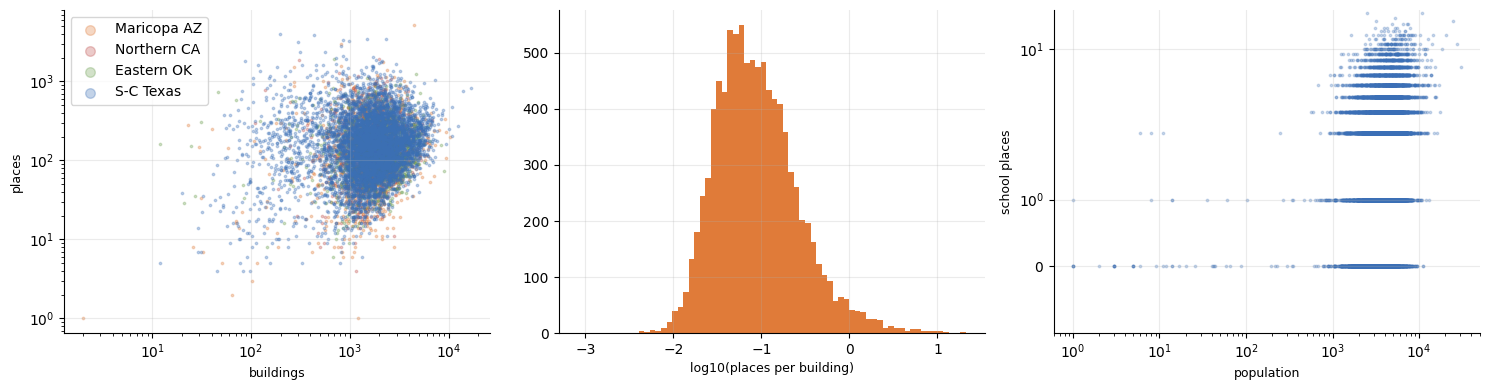

In [5]:
cols = ["pop_total", "housing_units", "land_km2", "bldg_n"]
print(s[["poi_n", "poi_n_fire", "poi_n_ems", "poi_n_school", "poi_n_hospital"]].apply(lambda y: pd.Series({x: y.corr(s[x], method="spearman") for x in cols})).round(3).T.to_string())
q = s.assign(ur=s.ur_class.fillna("unclassified"))
print("\nshare of tracts with at least one, by urban class:"); print(q.groupby("ur")[["poi_n", "poi_n_fire", "poi_n_ems", "poi_n_school", "poi_n_hospital"]].agg(lambda x: (x > 0).mean()).round(3).to_string())
print("\nplaces per building (median) by urban class:", q.groupby("ur").poi_per_bldg.median().round(3).to_dict())
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for r in SCORED: z = s[(s.region == r) & (s.poi_n > 0) & (s.bldg_n > 0)]; ax[0].scatter(z.bldg_n, z.poi_n, s=3, alpha=.3, c=COL[r], label=NAME[r])
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("buildings"); ax[0].set_ylabel("places"); ax[0].legend(markerscale=4)
ax[1].hist(np.log10(s.poi_per_bldg[s.poi_per_bldg > 0]), bins=70, color="#e07b39"); ax[1].set_xlabel("log10(places per building)")
z = s[s.pop_total > 0]; ax[2].scatter(z.pop_total, z.poi_n_school, s=3, alpha=.25, c="#3b6fb6"); ax[2].set_xscale("log"); ax[2].set_yscale("symlog"); ax[2].set_xlabel("population"); ax[2].set_ylabel("school places")
plt.show()

**Takeaway:** Place counts follow structure only weakly: all places correlate 0.37 (Spearman) with housing units, 0.23 with population, 0.13 with buildings and 0.07 with land. Fire places follow land (0.35) and buildings (0.29) far more than population (0.05), EMS correlates at most 0.10 with anything, and schools sit at 0.23 to 0.30 with all four. Rural and urban tracts are equally likely to have a school (78% and 79%), but rural tracts more often contain a fire place (55% against 24%, mostly a size effect) and have fewer places per building (median 0.039 against 0.099). The POI component will therefore be harder to anticipate from structure than the building or road components.

## 5. Closed, low-confidence and uncategorised places by tract type
The establishments half of the hidden score counts *all* places, including permanently closed ones. How big is that share, and does it differ by urbanity or region?

In [6]:
q = s.assign(ur=s.ur_class.fillna("unclassified"), closed_share=lambda d: d.poi_n_closed / d.poi_n.where(d.poi_n > 0), lowconf=lambda d: 1 - d.poi_n_conf05 / d.poi_n.where(d.poi_n > 0), nocat_share=lambda d: d.poi_n_nocat / d.poi_n.where(d.poi_n > 0))
print(q.groupby("ur")[["closed_share", "lowconf", "nocat_share"]].median().round(3).to_string())
print("\nby region:"); print(q.groupby("region")[["closed_share", "lowconf", "nocat_share", "poi_conf_mean"]].median().loc[SCORED].round(3).to_string())
print("\ntracts with at least 10 places where more than 10% are permanently closed:", int(((q.poi_n >= 10) & (q.closed_share > .1)).sum()), "of", int((q.poi_n >= 10).sum()))

              closed_share  lowconf  nocat_share
ur                                              
Rural                0.000    0.135        0.033
Urban                0.017    0.100        0.042
unclassified         0.000    0.094        0.030

by region:
                  closed_share  lowconf  nocat_share  poi_conf_mean
region                                                             
maricopa-az              0.017    0.098        0.046          0.820
northern-ca              0.013    0.100        0.036          0.818
eastern-ok               0.012    0.103        0.036          0.817
south-central-tx         0.014    0.109        0.040          0.816

tracts with at least 10 places where more than 10% are permanently closed: 26 of 9327


**Takeaway:** Permanently closed places are few: the median tract has 1.2% to 1.7% by region, and only 26 of 9,327 tracts with at least 10 places have more than 10% closed. Low-confidence places (under 0.5) are 13.5% of places in the median rural tract and 10.0% in the median urban tract; places without a category are 3.3% rural and 4.2% urban. The hidden score counts all places, closed ones included, but these shares are small enough that they matter for few tracts.